# COMP 5112 — GAN for Imbalanced Fraud DetectionOmoniyi (1340808) · Fijabi (1298724)Explanations are in `COMP5112_Code_Explained.docx`.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ctgan imbalanced-learnimport warnings, time, syswarnings.filterwarnings("ignore")import numpy as np, pandas as pd, torchimport matplotlib.pyplot as pltsys.path.insert(0, "/content")print("GPU:", torch.cuda.is_available())

/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `pip install -q ctgan imbalanced-learnimport warnings, time, syswarnings.filterwarnings("ignore")import numpy as np, pandas as pd, torchimport matplotlib.pyplot as pltsys.path.insert(0, "/content")print("GPU:", torch.cuda.is_available())'


In [ ]:
import os, sys, glob, zipfile

if not os.path.isdir("/content/fraudgan"):
    zips = glob.glob("/content/*.zip")
    if not zips:
        from google.colab import files
        up = files.upload()               # pick the .zip, NOT the .ipynb
        zips = [f for f in up if f.lower().endswith(".zip")]
        if not zips:
            raise SystemExit(f"You chose {list(up)}. Re-run and pick COMP5112_GAN_Code.zip")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall("/content")
    print("extracted", zips[0])

sys.path.insert(0, "/content")
assert os.path.isdir("/content/fraudgan"), "fraudgan/ missing - did you pick the zip?"
print(sorted(os.listdir("/content/fraudgan")))

['__init__.py', '__pycache__', 'augment.py', 'data.py', 'evaluate.py', 'gan.py', 'prep.py', 'run.py']


In [ ]:
from fraudgan import make_demo, load_paysim, load_ieee, Config, run, summarise, table, vs_baseline, split, cap_majority, select_features, Cleaner, Encoder, TabularGAN, CTGANModel, diagnose, apply

## 2. Data

In [ ]:
from google.colab import files
files.upload()                      # kaggle.json
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle && mkdir -p /content/data

Saving kaggle.json to kaggle (1).json


In [ ]:
!kaggle datasets download -d ealaxi/paysim1 -p /content/data --unzip

# !kaggle competitions download -c ieee-fraud-detection -p /content/data# !unzip -oq /content/data/ieee-fraud-detection.zip -d /content/data!ls /content/data

Dataset URL: https://www.kaggle.com/datasets/ealaxi/paysim1
License(s): CC-BY-SA-4.0
100% 178M/178M [00:02<00:00, 91.6MB/s]



In [ ]:
!ls -la /content/data

total 1926148
drwxr-xr-x 2 root root      4096 Nov 15 07:13 .
drwxr-xr-x 1 root root      4096 Nov 15 07:12 ..
-rw-r--r-- 1 root root 123856947 Dec 11  2019 ieee-fraud-detection.zip
-rw-r--r-- 1 root root 493534783 Nov 15 07:13 PS_20174392719_1491204439457_log.csv
-rw-r--r-- 1 root root   6080314 Dec 11  2019 sample_submission.csv
-rw-r--r-- 1 root root  25797161 Dec 11  2019 test_identity.csv
-rw-r--r-- 1 root root 613194934 Dec 11  2019 test_transaction.csv
-rw-r--r-- 1 root root  26529680 Dec 11  2019 train_identity.csv
-rw-r--r-- 1 root root 683351067 Dec 11  2019 train_transaction.csv


In [ ]:
ds = load_paysim("/content/data/PS_20174392719_1491204439457_log.csv")
# ds = load_ieee("/content/data/train_transaction.csv", "/content/data/train_identity.csv")ds

In [ ]:
import glob
ds = load_paysim(glob.glob("/content/data/*.csv")[0])
ds

<PaySim: 6,362,620 rows, 9 features, 8,213 fraud (0.129%)>

## 3. Split and preprocess

In [ ]:
sp = split(ds, train_frac=0.70, val_frac=0.15, seed=0)
sp.counts()

train = cap_majority(sp.train, ds.target, limit=200_000, seed=0)
num, cat, imp = select_features(train, ds.target, ds.categorical,
                                k=50, seed=0, exclude=[ds.time_col])
print(len(num), "numeric +", len(cat), "categorical")
imp.head(10)

cleaner = Cleaner(num, cat, ds.target)
tr = cleaner.fit_transform(train)
va = cleaner.transform(sp.val)
te = cleaner.transform(sp.test)

fraud = tr[tr[ds.target] == 1].drop(columns=[ds.target])
print(len(fraud), "fraud rows available to the generator")
fraud.head()


7 numeric + 1 categorical
5749 fraud rows available to the generator


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,type
26,1318024.48,1318024.48,0.0,0.0,0.0,0.0,1318024.48,TRANSFER
116,6339.42,6339.42,0.0,0.0,0.0,0.0,6339.42,TRANSFER
117,196385.55,196385.55,0.0,0.0,0.0,0.0,196385.55,TRANSFER
133,115461.48,115461.48,0.0,0.0,0.0,0.0,115461.48,TRANSFER
177,489514.32,489514.32,0.0,0.0,0.0,0.0,489514.32,TRANSFER


In [ ]:
f = tr[tr[ds.target] == 1]
n = tr[tr[ds.target] == 0]
print("fraud   : errDest==amount in %.1f%%, type mix %s"
      % (100*(f.errorBalanceDest.round(2) == f.amount.round(2)).mean(), dict(f.type.value_counts())))
print("legit   : errDest==amount in %.1f%%"
      % (100*(n.errorBalanceDest.round(2) == n.amount.round(2)).mean()))

fraud   : errDest==amount in 49.9%, type mix {'TRANSFER': np.int64(2876), 'CASH_OUT': np.int64(2873)}
legit   : errDest==amount in 36.3%


## 4. Train the GAN

# Training the Generator and distributor


In [ ]:
import time, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("ok")

ok


/content/fraudgan/gan.py:193: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  d_running += float(d_loss)


  epoch    0  D +1.7236  G -0.5226
  epoch   50  D +0.0321  G -1.4567
  epoch  100  D +0.0297  G -1.5698
  epoch  150  D +0.0336  G -1.4534
  epoch  200  D +0.0334  G -1.4685
  epoch  250  D +0.0399  G -1.3932
  epoch  299  D +0.0319  G -1.3892
462s


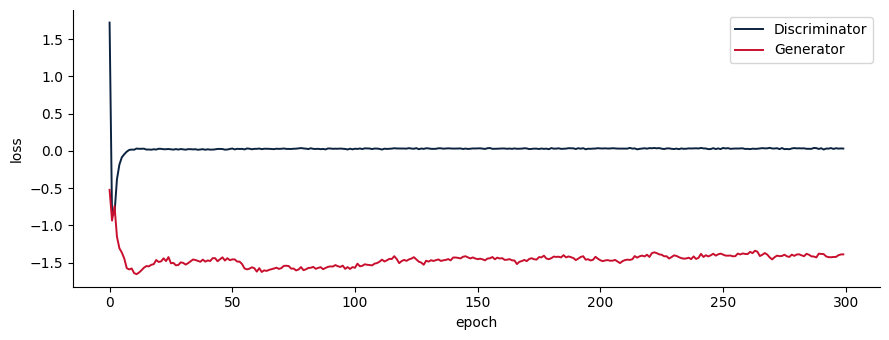

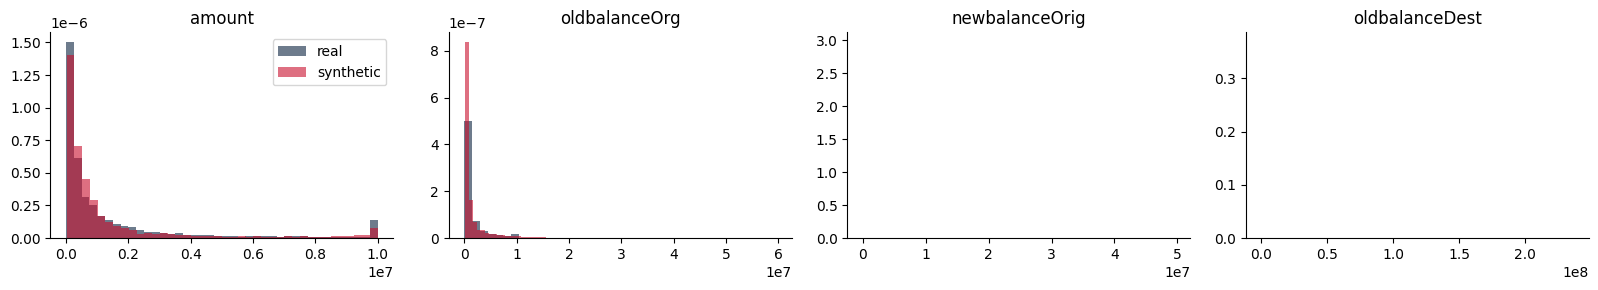

In [ ]:
gan = TabularGAN(z_dim=128, hidden=(256, 256), batch_size=256,
                 epochs=300, lr=2e-4, n_critic=2, seed=0, verbose=True)

t0 = time.time()
gan.fit(fraud, numeric=num, categorical=cat)
print(f"{time.time()-t0:.0f}s")

h = gan.loss_history()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(h.epoch, h.d_loss, label="Discriminator", lw=1.4, color="#0C2340")
ax.plot(h.epoch, h.g_loss, label="Generator", lw=1.4, color="#C8102E")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

synth = gan.sample(5000)
synth.head()

d = diagnose(fraud, synth, num, cat, seed=0)
pd.Series(d.row())

cols = num[:4]
fig, axes = plt.subplots(1, len(cols), figsize=(4*len(cols), 3))
for ax, c in zip(np.atleast_1d(axes), cols):
    ax.hist(fraud[c], bins=40, alpha=.6, density=True, label="real", color="#0C2340")
    ax.hist(synth[c], bins=40, alpha=.6, density=True, label="synthetic", color="#C8102E")
    ax.set_title(c); ax.spines[["top","right"]].set_visible(False)
np.atleast_1d(axes)[0].legend()
plt.tight_layout(); plt.show()

In [ ]:
for c in num:
    print(f"{c:<20} unique={fraud[c].nunique():>6}  zeros={100*(fraud[c]==0).mean():5.1f}%")

amount               unique=  3603  zeros=  0.2%
oldbalanceOrg        unique=  3679  zeros=  0.5%
newbalanceOrig       unique=    98  zeros= 98.2%
oldbalanceDest       unique=  1994  zeros= 65.3%
newbalanceDest       unique=  2846  zeros= 49.9%
errorBalanceOrig     unique=    34  zeros= 99.4%
errorBalanceDest     unique=  2926  zeros= 35.2%


## 5. Check the generated data

In [ ]:
!pip install -q ctgan

In [ ]:
print(diagnose(fraud, synth, num, cat, seed=0).row())

{'marginal_similarity': 0.7214, 'diversity_ratio': 0.9047, 'duplication_rate': 0.0, 'coverage': 0.0, 'verdict': 'poor coverage'}


## 6. Full experiment

In [ ]:
cfg = Config(conditions=["none","smote","tabular_gan","ctgan"], classifiers=["logistic_regression","random_forest"], seeds=[0], ratio=0.10, max_majority=200_000, max_features=50, gan_epochs=300, gan_batch=256, ctgan_epochs=300, ctgan_batch=500)

results = run(ds, cfg)

results.to_csv("/content/results_paysim_seed0.csv", index=False)

cfg = Config(conditions=["none","smote","tabular_gan","ctgan"], classifiers=["logistic_regression","random_forest"], seeds=[0,1,2,3,4], ratio=0.10, max_majority=200_000, max_features=50, gan_epochs=300, gan_batch=256, ctgan_epochs=300, ctgan_batch=500)

<PaySim: 6,362,620 rows, 9 features, 8,213 fraud (0.129%)>

seed 0: train 205,749 (5,749 fraud), 7+1 features
   none              logistic_regression   PR-AUC 0.6251  MCC 0.6282  rec 0.508  prec 0.778     1.0s
   none              random_forest         PR-AUC 0.9981  MCC 0.9984  rec 0.997  prec 1.000    74.9s
   smote             logistic_regression   PR-AUC 0.6149  MCC 0.6305  rec 0.497  prec 0.801     7.3s
   smote             random_forest         PR-AUC 0.9981  MCC 0.9984  rec 0.997  prec 1.000    83.0s
   tabular_gan       logistic_regression   PR-AUC 0.6399  MCC 0.6291  rec 0.537  prec 0.739   460.4s
   tabular_gan       random_forest         PR-AUC 0.9980  MCC 0.9972  rec 0.997  prec 0.998   529.0s
   ctgan             logistic_regression   PR-AUC 0.6117  MCC 0.6112  rec 0.509  prec 0.735   304.1s
   ctgan             random_forest         PR-AUC 0.9977  MCC 0.9891  rec 0.997  prec 0.982   411.4s
   seed done in 1269s


## 7. Results

In [ ]:
summarise(results)[["condition", "classifier",                    "test_pr_auc_mean", "test_pr_auc_std",                    "test_mcc_mean", "test_mcc_std", "total_s_mean"]]
table(results, "test_pr_auc")

dataset,condition,classifier,PaySim
0,ctgan,logistic_regression,0.6117 ± 0.0000
1,ctgan,random_forest,0.9977 ± 0.0000
2,none,logistic_regression,0.6251 ± 0.0000
3,none,random_forest,0.9981 ± 0.0000
4,smote,logistic_regression,0.6149 ± 0.0000
5,smote,random_forest,0.9981 ± 0.0000
6,tabular_gan,logistic_regression,0.6399 ± 0.0000
7,tabular_gan,random_forest,0.9980 ± 0.0000


In [ ]:
vs_baseline(results, "test_pr_auc")

,dataset,classifier,condition,baseline,mean,delta,noise,beats_noise
0,PaySim,logistic_regression,ctgan,0.6251,0.6117,-0.0135,0.0,True
1,PaySim,logistic_regression,smote,0.6251,0.6149,-0.0102,0.0,True
2,PaySim,logistic_regression,tabular_gan,0.6251,0.6399,0.0147,0.0,True
3,PaySim,random_forest,ctgan,0.9981,0.9977,-0.0005,0.0,True
4,PaySim,random_forest,smote,0.9981,0.9981,-0.0000,0.0,True
5,PaySim,random_forest,tabular_gan,0.9981,0.9980,-0.0001,0.0,True


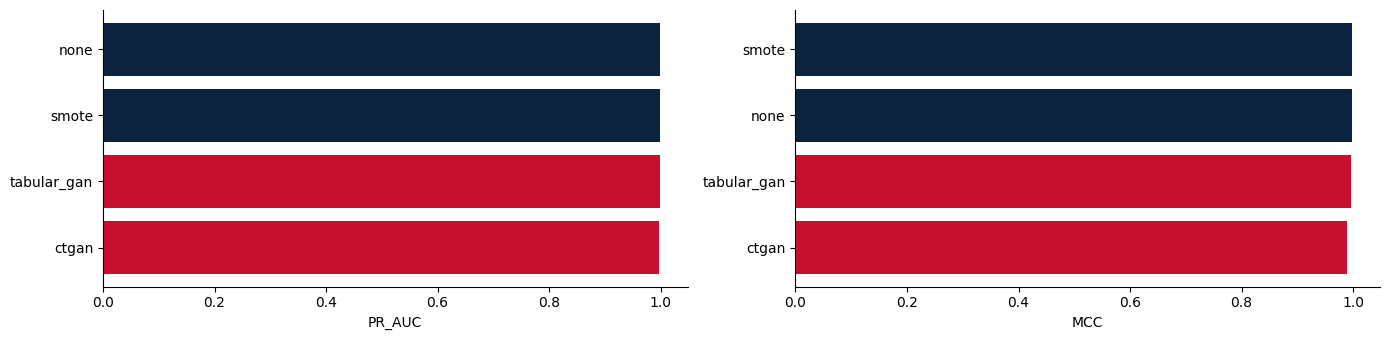

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, m in zip(axes, ["test_pr_auc", "test_mcc"]):
    g = results[results.classifier == "random_forest"].groupby("condition")[m].mean().sort_values()
    ax.barh(g.index, g.values, color=["#C8102E" if "gan" in c else "#0C2340" for c in g.index])
    ax.set_xlabel(m.replace("test_", "").upper())
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [ ]:
results.to_csv("/content/results_paysim_fullfraud_seed0.csv", index=False)

## 8. Second dataset

In [ ]:
# ds2 = load_ieee("/content/data/train_transaction.csv", "/content/data/train_identity.csv")# results2 = run(ds2, cfg)# all_results = pd.concat([results, results2], ignore_index=True)# all_results.to_csv("/content/results_all.csv", index=False)# table(all_results, "test_pr_auc")

Importing the IEEE-CIS Dataset froom Kaggle

In [ ]:
!kaggle competitions download -c ieee-fraud-detection -p /content/data
!unzip -oq /content/data/ieee-fraud-detection.zip -d /content/data

ieee-fraud-detection.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!ls /content/data

ieee-fraud-detection.zip	      test_transaction.csv
PS_20174392719_1491204439457_log.csv  train_identity.csv
sample_submission.csv		      train_transaction.csv
test_identity.csv


In [ ]:
from fraudgan import load_ieee

In [ ]:
ieee = load_ieee("/content/data/train_transaction.csv", "/content/data/train_identity.csv")
ieee

<IEEE-CIS: 590,540 rows, 432 features, 20,663 fraud (3.499%)>

1 Seed 4 Conditions

In [ ]:
cfg = Config(conditions=["none","smote","tabular_gan"], classifiers=["random_forest"], seeds=[0], ratio=0.10, max_majority=100_000, max_features=30, gan_epochs=150, gan_batch=256)

In [ ]:
results_ieee = run(ieee, cfg)

<IEEE-CIS: 590,540 rows, 432 features, 20,663 fraud (3.499%)>


/content/fraudgan/prep.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rank[c] = s.fillna(s.median())
/content/fraudgan/prep.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rank[c] = s.fillna(s.median())
/content/fraudgan/prep.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rank[c] = s


seed 0: train 114,464 (14,464 fraud), 27+3 features
   none              random_forest         PR-AUC 0.6010  MCC 0.5594  rec 0.527  prec 0.624    44.2s
   smote             random_forest         PR-AUC 0.6010  MCC 0.5594  rec 0.527  prec 0.624    51.4s
   tabular_gan       random_forest         PR-AUC 0.6010  MCC 0.5594  rec 0.527  prec 0.624    50.3s
   seed done in 227s


In [ ]:
results_ieee.to_csv("/content/results_ieee_ratio03_seed0.csv", index=False)

In [ ]:
cfg = Config(conditions=["none","smote","tabular_gan"], classifiers=["random_forest"], seeds=[1,2], ratio=0.30, max_majority=100_000, max_features=30, gan_epochs=150, gan_batch=256)

In [ ]:
results_ieee_2 = run(ieee, cfg)

<IEEE-CIS: 590,540 rows, 432 features, 20,663 fraud (3.499%)>


/content/fraudgan/prep.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rank[c] = s.fillna(s.median())
/content/fraudgan/prep.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rank[c] = s.fillna(s.median())
/content/fraudgan/prep.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rank[c] = s


seed 1: train 114,464 (14,464 fraud), 27+3 features
   none              random_forest         PR-AUC 0.6138  MCC 0.5888  rec 0.526  prec 0.687    50.6s
   smote             random_forest         PR-AUC 0.6118  MCC 0.5864  rec 0.534  prec 0.673    83.7s
   tabular_gan       random_forest         PR-AUC 0.6102  MCC 0.5833  rec 0.541  prec 0.658   834.0s
   seed done in 1066s


## 9. Temporal check (optional)

In [ ]:
import os
print("app.py:", os.path.exists("/content/app.py"))
print("fraudgan:", os.path.isdir("/content/fraudgan"))

app.py: False
fraudgan: True


In [ ]:
from google.colab import files
up = files.upload()        # pick app.py
import shutil, os
shutil.move(list(up)[0], "/content/app.py")
print("app.py:", os.path.exists("/content/app.py"))

Saving GAN_GUIapp.py to GAN_GUIapp.py
app.py: True


In [ ]:
!pip install -q streamlit
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠴

In [ ]:
!pkill -f streamlit
!streamlit run /content/app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/st.log &
!sleep 10

from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-ase1a1-1u29z5gpkvvec-a.asia-east1.prod.r.colab.dev


In [ ]:
# cell 1 — upload the zip
import zipfile, glob, sys, os
from google.colab import files
if not os.path.isdir("/content/fraudgan"):
    up = files.upload()
    with zipfile.ZipFile([f for f in up if f.endswith(".zip")][0]) as z:
        z.extractall("/content")
sys.path.insert(0, "/content")
print(os.path.exists("/content/app.py"), os.path.isdir("/content/fraudgan"))

Saving COMP5112_GAN_Code.zip to COMP5112_GAN_Code.zip
True True


In [ ]:
# cell 2 — launch
!pip install -q streamlit ctgan imbalanced-learn
!streamlit run /content/app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/st.log &
!sleep 12
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-ase1a1-1u29z5gpkvvec-a.asia-east1.prod.r.colab.dev


In [ ]:
from google.colab import files
files.upload()          # pick kaggle.json
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle && mkdir -p /content/data
!kaggle datasets download mlg-ulb/creditcardfraud -p /content/data

import zipfile
with zipfile.ZipFile("/content/data/creditcardfraud.zip") as z:
    z.extractall("/content/data")
!ls -la /content/data

Saving kaggle (1).json to kaggle (1).json
cp: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:04<00:00, 17.2MB/s]

total 214848
drwxr-xr-x 2 root root      4096 Nov 16 22:44 .
drwxr-xr-x 1 root root      4096 Nov 16 22:43 ..
-rw-r--r-- 1 root root 150828752 Nov 16 22:44 creditcard.csv
-rw-r--r-- 1 root root  69155672 Sep 20  2019 creditcardfraud.zip


In [ ]:
import pandas as pd
df = pd.read_csv("/content/data/creditcard.csv")
print("full:", df.shape, int(df.Class.sum()), "fraud")

fraud = df[df.Class == 1]
legit = df[df.Class == 0].sample(60000, random_state=0)
small = pd.concat([fraud, legit]).sample(frac=1, random_state=0).reset_index(drop=True)
small.to_csv("/content/ulb_creditcard_demo.csv", index=False)

print("demo file:", small.shape, f"{small.Class.mean()*100:.2f}% fraud")
files.download("/content/ulb_creditcard_demo.csv")

full: (284807, 31) 492 fraud
demo file: (60492, 31) 0.81% fraud


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# cell 1 — upload the zip
import zipfile, glob, sys, os
from google.colab import files
if not os.path.isdir("/content/fraudgan"):
    up = files.upload()
    with zipfile.ZipFile([f for f in up if f.endswith(".zip")][0]) as z:
        z.extractall("/content")
sys.path.insert(0, "/content")
print(os.path.exists("/content/app.py"), os.path.isdir("/content/fraudgan"))

True True


In [ ]:
# cell 2 — launch
!pip install -q streamlit ctgan imbalanced-learn
!streamlit run /content/app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/st.log &
!sleep 12
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-ase1a1-1u29z5gpkvvec-a.asia-east1.prod.r.colab.dev


In [ ]:
# cfg_t = Config(conditions=["none", "smote", "tabular_gan"],#                classifiers=["random_forest"], seeds=[0],#                temporal=True, ratio=0.10, gan_epochs=300)# run(ds, cfg_t)[["condition", "test_pr_auc", "test_mcc", "test_recall"]]